<a href="https://colab.research.google.com/github/Radhika-238/customer-purchase-prediction/blob/main/Customer_Purchase_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [176]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [177]:
df = pd.read_csv('online_shoppers_intention.csv')
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [178]:
df.describe()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,2.124006,2.357097,3.147364,4.069586
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,0.911325,1.717277,2.401591,4.025169
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000


In [179]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

In [180]:
df.duplicated().sum()

np.int64(125)

In [181]:
(df['Revenue'] == 1).sum()

np.int64(1908)

In [182]:
df['Revenue'].value_counts()

,count
Revenue,
False,10422
True,1908


In [183]:
for col in df.columns:
    print(f'{col} - {df[col].value_counts()}')

Administrative - Administrative
0     5768
1     1354
2     1114
3      915
4      765
5      575
6      432
7      338
8      287
9      225
10     153
11     105
12      86
13      56
14      44
15      38
16      24
17      16
18      12
19       6
24       4
22       4
23       3
21       2
20       2
27       1
26       1
Name: count, dtype: int64
Administrative_Duration - Administrative_Duration
0.000000      5903
4.000000        56
5.000000        53
7.000000        45
11.000000       42
              ... 
65.600000        1
552.200000       1
206.250000       1
401.150000       1
315.966667       1
Name: count, Length: 3335, dtype: int64
Informational - Informational
0     9699
1     1041
2      728
3      380
4      222
5       99
6       78
7       36
9       15
8       14
10       7
12       5
14       2
16       1
11       1
24       1
13       1
Name: count, dtype: int64
Informational_Duration - Informational_Duration
0.000000       9925
9.000000         33
10.000000      

In [184]:
df_encoded = pd.get_dummies(
    df,
    columns = ['VisitorType'],
    dtype = int
)
df_encoded.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,Weekend,Revenue,VisitorType_New_Visitor,VisitorType_Other,VisitorType_Returning_Visitor
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,False,False,0,0,1
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,False,False,0,0,1
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,False,False,0,0,1
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,False,False,0,0,1
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,True,False,0,0,1


In [185]:
df_encoded['Revenue'] = df_encoded['Revenue'].astype(int)
df_encoded['Weekend'] = df_encoded['Weekend'].astype(int)
df_encoded.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,Weekend,Revenue,VisitorType_New_Visitor,VisitorType_Other,VisitorType_Returning_Visitor
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,0,0,0,0,1
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,0,0,0,0,1
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,0,0,0,0,1
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,0,0,0,0,1
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,1,0,0,0,1


In [186]:
month_map = {
    'Feb': 2, 'Mar': 3, 'May': 5,
    'June': 6, 'Jul': 7, 'Aug': 8,
    'Sep': 9, 'Oct': 10, 'Nov': 11, 'Dec': 12
}

df_encoded['Month'] = df_encoded['Month'].map(month_map)

In [187]:
df_corr = df_encoded.corr()['Revenue']
df_corr.sort_values(ascending = False)

,Revenue
Revenue,1.000000
PageValues,0.492569
ProductRelated,0.158538
ProductRelated_Duration,0.152373
Administrative,0.138917
Month,0.127372
VisitorType_New_Visitor,0.104136
Informational,0.095200
Administrative_Duration,0.093587
Informational_Duration,0.070345


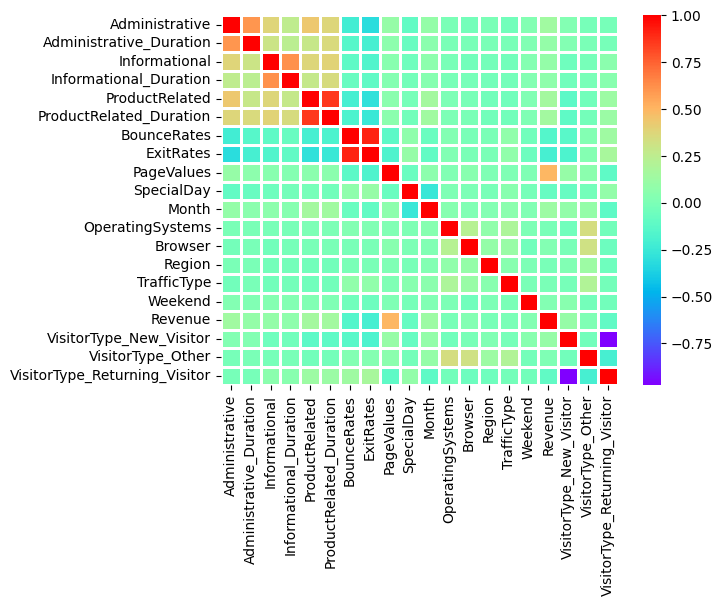

In [188]:
sns.heatmap(df_encoded.corr(), cmap = 'rainbow', linecolor= 'white', linewidths= 2)
plt.show()

In [189]:
x = df.drop(['Revenue'], axis = 1)
y = df['Revenue']
x_train, x_test, y_train, y_test = train_test_split(x, y, train_size = 0.8, random_state = 42, stratify = y)

In [190]:
x_train.dtypes

,0
Administrative,int64
Administrative_Duration,float64
Informational,int64
Informational_Duration,float64
ProductRelated,int64
ProductRelated_Duration,float64
BounceRates,float64
ExitRates,float64
PageValues,float64
SpecialDay,float64


In [191]:
x_train.select_dtypes(include=['object']).value_counts()

,,count
Month,VisitorType,
May,Returning_Visitor,2449
Nov,Returning_Visitor,2014
Mar,Returning_Visitor,1355
Dec,Returning_Visitor,1069
Oct,Returning_Visitor,339
Nov,New_Visitor,326
Jul,Returning_Visitor,304
Aug,Returning_Visitor,286
Sep,Returning_Visitor,276


In [192]:
cat_col = ['Month', 'VisitorType', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'Weekend']
x_train_num = x_train.drop(cat_col, axis = 1)
x_train_cat = x_train[cat_col]
x_train_num.columns

Index(['Administrative', 'Administrative_Duration', 'Informational',
       'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration',
       'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay'],
      dtype='object')

In [193]:
from sklearn.preprocessing import OneHotEncoder
ohe = OneHotEncoder(handle_unknown = 'ignore', sparse_output = False)
x_train_cat_ohe = ohe.fit_transform(x_train_cat)
x_train_cat_ohe.shape

(9864, 65)

In [194]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_train_num_scaled = scaler.fit_transform(x_train_num)
x_train_num_scaled.shape

(9864, 10)

In [195]:
x_train_final = np.hstack((x_train_num_scaled, x_train_cat_ohe))

In [196]:
x_test_cat = x_test[cat_col]
x_test_num = x_test.drop(cat_col, axis = 1)
x_test_cat.columns

Index(['Month', 'VisitorType', 'OperatingSystems', 'Browser', 'Region',
       'TrafficType', 'Weekend'],
      dtype='object')

In [197]:
x_test_cat_ohe = ohe.transform(x_test_cat)
x_test_num_scaled = scaler.transform(x_test_num)

In [198]:
x_test_final = np.hstack((x_test_num_scaled, x_test_cat_ohe))

In [199]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score
model = LogisticRegression()
model.fit(x_train_final, y_train)
y_pred = model.predict(x_test_final)
print('accuracy- ', accuracy_score(y_test, y_pred))
print('confusion matrix- \n', confusion_matrix(y_test, y_pred))
print('f1_score- ', f1_score(y_test, y_pred))
print('precision- ', precision_score(y_test, y_pred))
print('recall- ', recall_score(y_test, y_pred))

accuracy-  0.8807785888077859
confusion matrix- 
 [[2035   49]
 [ 245  137]]
f1_score-  0.4823943661971831
precision-  0.7365591397849462
recall-  0.3586387434554974


In [200]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score
model = LogisticRegression(max_iter = 1000, class_weight = 'balanced')
model.fit(x_train_final, y_train)
y_pred = model.predict(x_test_final)
print('accuracy- ', accuracy_score(y_test, y_pred))
print('confusion matrix- \n', confusion_matrix(y_test, y_pred))
print('f1_score- ', f1_score(y_test, y_pred))
print('precision- ', precision_score(y_test, y_pred))
print('recall- ', recall_score(y_test, y_pred))

accuracy-  0.8410381184103812
confusion matrix- 
 [[1790  294]
 [  98  284]]
f1_score-  0.5916666666666667
precision-  0.4913494809688581
recall-  0.743455497382199


In [201]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

In [202]:
preprocessor = ColumnTransformer(
    transformers = [
        ('num', StandardScaler(), x_train_num.columns.tolist()),
        ('cat', OneHotEncoder(handle_unknown = 'ignore', sparse_output = False), cat_col)
    ]
)

In [203]:
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(max_iter = 1000, class_weight = 'balanced'))
])

In [204]:
cross_val = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 42)
score = cross_val_score(
    pipeline, x_train, y_train, cv = cross_val, scoring = 'f1'
)

In [205]:
print("F1 Scores:", score)
print("Mean F1:", np.mean(score))
print("Standard Deviation:", np.std(score))

F1 Scores: [0.59173127 0.63382157 0.59067358 0.64383562 0.62450593]
Mean F1: 0.6169135915619728
Standard Deviation: 0.0218678154431082


In [206]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [207]:
preprocessor = ColumnTransformer(
    transformers = [
        ('num', StandardScaler(), x_train_num.columns.tolist()),
        ('cat', OneHotEncoder(handle_unknown = 'ignore', sparse_output = False), cat_col)
    ]
)

In [208]:
pipeline = Pipeline([
    ('rf_preprocessor', preprocessor),
    ('rf_model', RandomForestClassifier(n_estimators = 100, random_state = 42))
])

In [209]:
cv = StratifiedKFold(n_splits= 5, random_state = 42, shuffle = True)
score = cross_val_score(
    pipeline, x_train, y_train, cv=cv, scoring = 'f1'
)

In [210]:
print("F1 Scores:", score)
print("Mean F1:", np.mean(score))
print("Standard Deviation:", np.std(score))

F1 Scores: [0.59448819 0.60159363 0.59961315 0.62645914 0.63601533]
Mean F1: 0.6116338873836795
Standard Deviation: 0.016453100973235414


In [211]:
from sklearn.model_selection import GridSearchCV
param_grid = {
    'rf_model__n_estimators' : [100, 150, 200, 250],
    'rf_model__max_depth' : [2, 3, 5, None],
    'rf_model__min_samples_split' : [2, 5]
}
gs = GridSearchCV(pipeline, param_grid, cv=cv, scoring = 'f1', n_jobs = -1)

In [212]:
gs.fit(x_train, y_train)
print('best parameters: ', gs.best_params_)
print('best f1 score: ', gs.best_score_)

best parameters:  {'rf_model__max_depth': None, 'rf_model__min_samples_split': 5, 'rf_model__n_estimators': 150}
best f1 score:  0.6238019038297182


In [213]:
best_pipeline = gs.best_estimator_
best_rf = best_pipeline.named_steps['rf_model']
importance = best_rf.feature_importances_
feature_names = best_pipeline.named_steps[
    'rf_preprocessor'
].get_feature_names_out()
feature_df = pd.DataFrame({
    'feature' : feature_names,
    'importance': importance
})

feature_df.sort_values(by = 'importance', ascending = False)

,feature,importance
8,num__PageValues,3.640335e-01
7,num__ExitRates,8.055154e-02
5,num__ProductRelated_Duration,7.642475e-02
4,num__ProductRelated,6.457308e-02
1,num__Administrative_Duration,5.027216e-02
...,...,...
67,cat__TrafficType_15,4.628221e-05
39,cat__Browser_9,2.315643e-06
70,cat__TrafficType_18,6.669978e-07
64,cat__TrafficType_12,4.020287e-07


In [214]:
y_pred_rf = best_pipeline.predict(x_test)
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1 Score:", f1_score(y_test, y_pred_rf))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))

Accuracy: 0.8965936739659367
Precision: 0.7550200803212851
Recall: 0.49214659685863876
F1 Score: 0.595879556259905
Confusion Matrix:
 [[2023   61]
 [ 194  188]]


Joblib is a Python library used to save and load trained Machine Learning models.

In [215]:
import joblib
joblib.dump(best_pipeline, 'customer_purchase_prediction.pkl')
loaded_model = joblib.load('customer_purchase_prediction.pkl')
predictions = loaded_model.predict(x_test)

In [216]:
np.array_equal(predictions, y_pred_rf)

True